---
title: "Improving TabPFN Performance with Thinking Mode"
description: "Compare baseline TabPFN and thinking mode on two regression datasets."
cookbookTags:
  - thinking mode
  - api
  - regression
authors:
  - name: Eliott Kalfon
    linkedin: https://www.linkedin.com/in/eliott-kalfon/
featured: true
---

# Improving TabPFN Performance with Thinking Mode

*The simplest, strongest way to push TabPFN further.*

TabPFN is strong out of the box. The newest and most powerful way to improve it is **thinking mode**: TabPFN-3-Thinking spends extra compute at fit time to deliver better predictions, enabled with a single flag. You pay the optimisation cost once at fit time, and every prediction afterwards benefits.

Thinking mode runs on the hosted API client (`tabpfn-client`), so this whole notebook uses the client. We try it on two price-prediction datasets, one where TabPFN is already very strong and one that is harder, to see what the extra compute buys.

## Setup

*Install, authenticate, and import.*

In [ ]:
!pip install -q "tabpfn-client>=0.7.1" scikit-learn numpy pandas matplotlib

In [1]:
import os

from google.colab import userdata

os.environ["TABPFN_TOKEN"] = userdata.get('TABPFN_TOKEN')

In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from tabpfn_client import TabPFNRegressor

warnings.filterwarnings("ignore")

SEED = 0

## Data Loaders

*Two price-prediction datasets.*

`diamonds` is already easy for TabPFN (R² above 0.98); `house_sales` has more headroom. A single loader handles OpenML's mixed categorical/numeric frames: categoricals are ordinal-encoded and missing values are filled.

In [3]:
# @title
def load_openml_regression(data_id):
    """Fetch an OpenML regression frame and return (X, y) as numpy.
    Categoricals are ordinal-encoded and missing values filled."""
    d = fetch_openml(data_id=data_id, as_frame=True, parser="auto")
    X, y = d.data.copy(), pd.to_numeric(d.target)
    cat = [c for c in X.columns if str(X[c].dtype) in ("category", "object", "string")]
    num = [c for c in X.columns if c not in cat]
    if cat:
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        X[cat] = enc.fit_transform(X[cat].astype(str))
    X[num] = X[num].apply(pd.to_numeric, errors="coerce")
    X = X.fillna(X.median(numeric_only=True)).fillna(-1)
    return X.to_numpy(dtype=float), y.to_numpy(dtype=float)


def load_diamonds():
    """diamonds: 53,940 diamonds x 9 features (carat, cut, color, clarity,
    dimensions); target is price in USD."""
    return load_openml_regression(42225)


def load_house_sales():
    """house_sales: 21,613 King County home sales x 21 features (size, rooms,
    condition, location); target is sale price in USD."""
    return load_openml_regression(42731)

## Model Helpers

*Building the client classifier and scoring.*

`build_regressor` returns the hosted API client (every fit runs on it). `score_reg` reports RMSE, MAE and R² side by side.

In [4]:
# @title
def build_regressor(**kwargs):
    """All fits run on the hosted API client (thinking mode is API only)."""
    return TabPFNRegressor(random_state=SEED, **kwargs)


def score_reg(model, Xte, yte):
    pred = np.asarray(model.predict(Xte), dtype=float)
    return {
        "rmse": float(np.sqrt(mean_squared_error(yte, pred))),
        "mae":  float(mean_absolute_error(yte, pred)),
        "r2":   float(r2_score(yte, pred)),
    }

### Thinking mode (TabPFN-3-Thinking)

*Spend more compute at fit time, get better predictions.*

Thinking mode applies test-time compute scaling to TabPFN. Instead of a single forward pass, TabPFN-3-Thinking runs an optimisation at fit time, and every prediction afterwards draws on that work. It is a single flag.

```python
from tabpfn_client import TabPFNRegressor

# Simplest form: enable with defaults (effort "medium")
model = TabPFNRegressor(thinking_mode=True)
model.fit(X_train, y_train)
model.predict(X_test)

# Or choose the effort level explicitly
model = TabPFNRegressor(thinking_effort="high")
```

`thinking_effort` ranges from fastest to most thorough: `"micro"`, `"mini"`, `"low"`, `"medium"`, `"high"`, `"xhigh"`, `"max"` (requires `tabpfn-client` 0.7.1+). `thinking_metric` targets the objective (regression: `rmse`, `mae`; classification: `accuracy`, `log_loss`, `roc_auc`, and more). See the [Thinking mode](https://docs.priorlabs.ai/capabilities/thinking-mode) page for details.

> Thinking runs an optimization over the training set at fit time, so a fit takes minutes rather than seconds and grows with the number of rows and features: about 7 minutes on diamonds (40,000 training rows) and 3 minutes on house sales (16,000) in this notebook. The cost is paid once at fit time; prediction speed is unchanged.

In [5]:
# @title
def thinking_kwargs(effort="high", metric=None):
    """Thinking mode: TabPFN-3-Thinking spends extra compute at fit time for better
    predictions. metric is one of rmse, mae for regression."""
    kw = {"thinking_effort": effort}
    if metric:
        kw["thinking_metric"] = metric
    return kw

## Test Runner

*One function to run a configuration, plus helpers to tabulate results.*

`run` fits a configuration on the client and scores it; `make_results_df` adds a column with the percentage RMSE reduction against the baseline.

In [6]:
# @title
def run(name, Xtr, Xte, ytr, yte, model_kwargs=None):
    """Fit a client regressor with the given kwargs and score it."""
    model_kwargs = model_kwargs or {}
    t0 = time.time()
    try:
        reg = build_regressor(**model_kwargs)
        reg.fit(Xtr, ytr)
        metrics = score_reg(reg, Xte, yte)
        metrics["n_features"] = Xtr.shape[1]
        del reg
    except Exception as e:
        print(f"  {name}: FAILED - {e}")
        metrics = {"n_features": np.nan}
    metrics["config"] = name
    metrics["secs"] = round(time.time() - t0, 1)
    return metrics


def make_results_df(rows, headline):
    df = pd.DataFrame(rows)
    base = df.loc[df.config == "baseline", headline].iloc[0]
    df["rmse_reduction_%"] = 100 * (base - df[headline]) / base
    return df


def show(df, headline, cols=None):
    cols = cols or ["config", headline, "n_features", "secs", "rmse_reduction_%"]
    display(df[cols].round(4).set_index("config"))

# Experiments

*Baseline versus thinking mode on each dataset.*

## Diamonds: a Strong Baseline

*Can thinking squeeze out the last bit of quality?*

The diamonds dataset predicts the price of a diamond from its carat, cut, color, clarity and dimensions (53,940 diamonds, 9 features). TabPFN is already excellent here out of the box (R² above 0.98), so the question is whether thinking mode can close any of the small remaining gap. We lead with **RMSE** in dollars and track MAE and R² alongside.

### Load the data

*The full dataset, with a 75/25 split.*

In [7]:
print("Loading diamonds ...")
X_dia, y_dia = load_diamonds()
print(f"Shape: {X_dia.shape}  |  mean price: ${y_dia.mean():,.0f}")

Xtr_dia, Xte_dia, ytr_dia, yte_dia = train_test_split(
    X_dia, y_dia, test_size=0.25, random_state=SEED
)

Loading diamonds ...
Shape: (53940, 9)  |  mean price: $3,933


### Baseline

*Default TabPFN on all 9 features, scored on RMSE.*

In [8]:
dia_rows = []
dia_rows.append(run("baseline", Xtr_dia, Xte_dia, ytr_dia, yte_dia))
print(f"RMSE: {dia_rows[-1]['rmse']:,.1f}")

RMSE: 491.7


### Thinking mode

*The same fit, with one extra flag.*

We optimise `rmse`, the same metric we report.

In [9]:
dia_rows.append(run(
    "thinking high (rmse)",
    Xtr_dia, Xte_dia, ytr_dia, yte_dia,
    model_kwargs=thinking_kwargs(effort="high", metric="rmse"),
))
print(f"RMSE: {dia_rows[-1]['rmse']:,.1f}")

RMSE: 483.7


### Results

In [10]:
df_dia = make_results_df(dia_rows, "rmse")
show(df_dia, "rmse",
     cols=["config", "rmse", "mae", "r2", "n_features", "secs", "rmse_reduction_%"])

,rmse,mae,r2,n_features,secs,rmse_reduction_%
config,,,,,,
baseline,491.7261,237.7638,0.9849,9,23.5,0.000
thinking high (rmse),483.7309,234.4880,0.9853,9,458.3,1.626


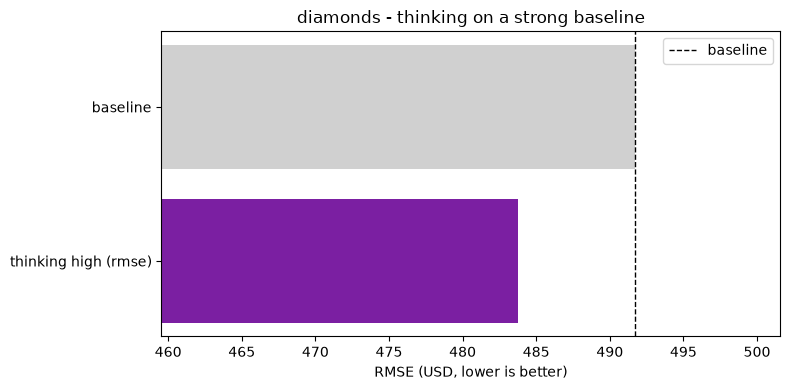

In [11]:
# @title
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#d0d0d0" if c == "baseline" else "#7B1FA2" for c in df_dia["config"]]
ax.barh(df_dia["config"], df_dia["rmse"], color=colors)
base = df_dia.loc[df_dia.config == "baseline", "rmse"].iloc[0]
ax.axvline(base, color="black", linestyle="--", linewidth=1, label="baseline")
ax.set_xlim(df_dia["rmse"].min() * 0.95, df_dia["rmse"].max() * 1.02)
ax.set_xlabel("RMSE (USD, lower is better)")
ax.set_title("diamonds - thinking on a strong baseline")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

## House Sales: a Harder Target

*Does the gain hold on a noisier problem?*

The house sales dataset predicts the sale price of homes in King County, Washington, from 21 features describing size, rooms, condition and location (21,613 sales). The baseline leaves more headroom than diamonds (R² around 0.94), so we check whether thinking delivers a similar gain here.

### Load the data

In [12]:
print("Loading house sales ...")
X_hs, y_hs = load_house_sales()
print(f"Shape: {X_hs.shape}  |  mean price: ${y_hs.mean():,.0f}")

Xtr_hs, Xte_hs, ytr_hs, yte_hs = train_test_split(
    X_hs, y_hs, test_size=0.25, random_state=SEED
)

Loading house sales ...
Shape: (21613, 21)  |  mean price: $540,088


### Baseline

In [13]:
hs_rows = []
hs_rows.append(run("baseline", Xtr_hs, Xte_hs, ytr_hs, yte_hs))
print(f"RMSE: {hs_rows[-1]['rmse']:,.1f}")

RMSE: 92,710.0


### Thinking mode

*The lever that moves the needle most here.*

In [14]:
hs_rows.append(run(
    "thinking high (rmse)",
    Xtr_hs, Xte_hs, ytr_hs, yte_hs,
    model_kwargs=thinking_kwargs(effort="high", metric="rmse"),
))
print(f"RMSE: {hs_rows[-1]['rmse']:,.1f}")

RMSE: 91,291.0


### Results

In [15]:
df_hs = make_results_df(hs_rows, "rmse")
show(df_hs, "rmse",
     cols=["config", "rmse", "mae", "r2", "n_features", "secs", "rmse_reduction_%"])

,rmse,mae,r2,n_features,secs,rmse_reduction_%
config,,,,,,
baseline,92710.0252,52209.0676,0.9353,21,4.7,0.0000
thinking high (rmse),91291.0290,51350.2921,0.9373,21,206.7,1.5306


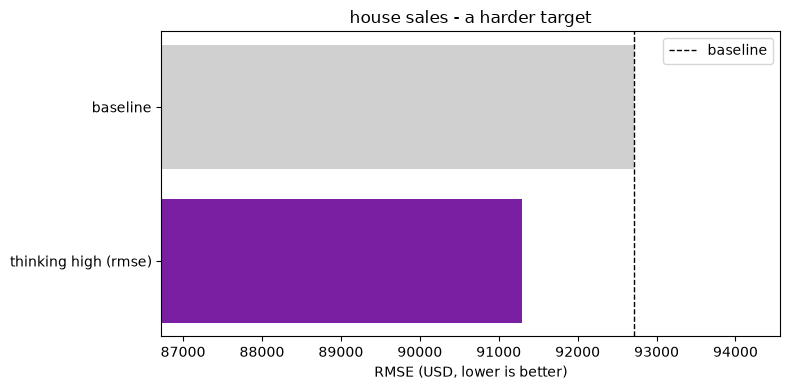

In [16]:
# @title
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#d0d0d0" if c == "baseline" else "#7B1FA2" for c in df_hs["config"]]
ax.barh(df_hs["config"], df_hs["rmse"], color=colors)
base = df_hs.loc[df_hs.config == "baseline", "rmse"].iloc[0]
ax.axvline(base, color="black", linestyle="--", linewidth=1, label="baseline")
ax.set_xlim(df_hs["rmse"].min() * 0.95, df_hs["rmse"].max() * 1.02)
ax.set_xlabel("RMSE (USD, lower is better)")
ax.set_title("house sales - a harder target")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

## Takeaways

- **Thinking mode is the simplest lever.** One flag (`thinking_mode=True`, or `thinking_effort="high"` as here) reduced RMSE, MAE and lifted R² on both datasets, with no feature engineering or tuning.
- **The gain is consistent.** RMSE fell by 1.6% on diamonds and 1.5% on house sales, so the strong baseline did not cap the improvement. Thinking never hurt a metric here.
- **It runs on the hosted client and the compute is paid once, at fit time.** Every prediction afterwards benefits, so reach for it first.